In [17]:
import random
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms
from sklearn.metrics import confusion_matrix, classification_report

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Библиотеки успешно загружены")

Библиотеки успешно загружены


In [2]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.2860,), (0.3530,))
])

train_dataset_full = datasets.FashionMNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.FashionMNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

print("Обучающая выборка:", len(train_dataset_full))
print("Тестовая выборка:", len(test_dataset))
print("Количество классов:", len(train_dataset_full.classes))

Обучающая выборка: 60000
Тестовая выборка: 10000
Количество классов: 10


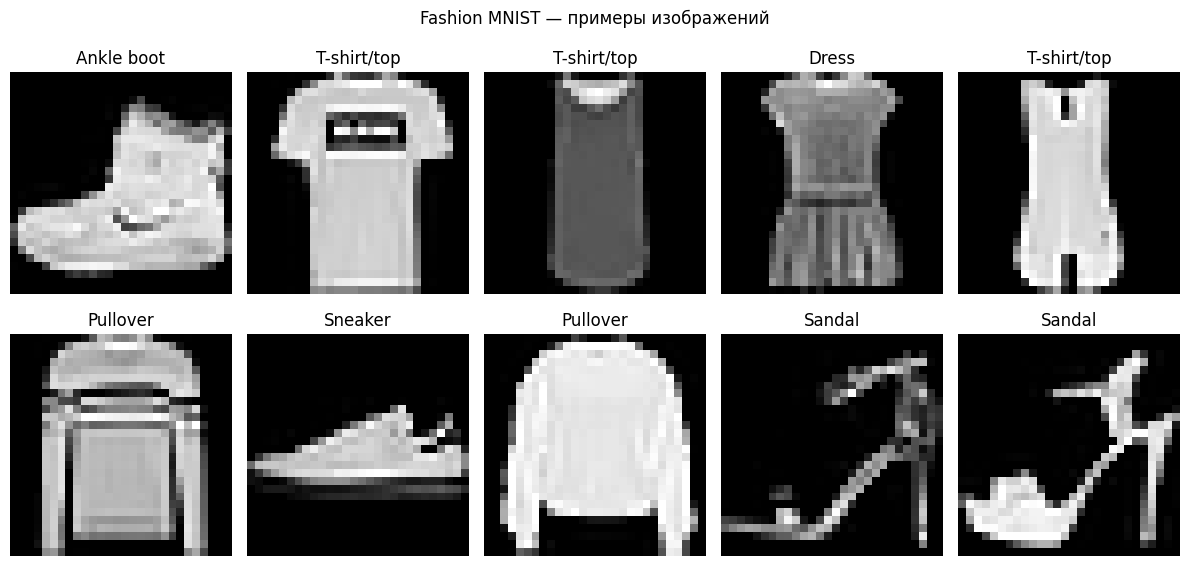

In [3]:
class_names = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot"
]

plt.figure(figsize=(12, 6))

for i in range(10):
    image, label = train_dataset_full[i]

    # Возвращаем пиксели к исходному диапазону
    image = image.squeeze() * 0.3530 + 0.2860

    plt.subplot(2, 5, i + 1)
    plt.imshow(image, cmap="gray")
    plt.title(class_names[label])
    plt.axis("off")

plt.suptitle("Fashion MNIST — примеры изображений")
plt.tight_layout()
plt.show()

In [5]:
train_dataset, val_dataset = random_split(
    train_dataset_full,
    [50000, 10000],
    generator=torch.Generator().manual_seed(42)
)

BATCH_SIZE = 256

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Train:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Test:", len(test_dataset))

Train: 50000
Validation: 10000
Test: 10000


In [7]:
class BasicMLP(nn.Module):
    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Flatten(),

            nn.Linear(784, 256),
            nn.ReLU(),

            nn.Linear(256, 128),
            nn.ReLU(),

            nn.Linear(128, 10)
        )

    def forward(self, x):
        return self.network(x)


model = BasicMLP().to(device)

print(model)

print(
    "Количество параметров:",
    sum(p.numel() for p in model.parameters())
)

BasicMLP(
  (network): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=256, bias=True)
    (2): ReLU()
    (3): Linear(in_features=256, out_features=128, bias=True)
    (4): ReLU()
    (5): Linear(in_features=128, out_features=10, bias=True)
  )
)
Количество параметров: 235146


In [9]:
criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

EPOCHS = 15

train_losses = []
train_accuracies = []
val_accuracies = []

for epoch in range(EPOCHS):

    # Обучение
    model.train()

    running_loss = 0
    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * labels.size(0)

        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    train_loss = running_loss / total
    train_acc = 100 * correct / total

    # Валидация
    model.eval()

    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            predictions = outputs.argmax(dim=1)

            val_correct += (
                predictions == labels
            ).sum().item()

            val_total += labels.size(0)

    val_acc = 100 * val_correct / val_total

    train_losses.append(train_loss)
    train_accuracies.append(train_acc)
    val_accuracies.append(val_acc)

    print(
        f"Эпоха {epoch + 1}/{EPOCHS} | "
        f"Loss: {train_loss:.4f} | "
        f"Train Accuracy: {train_acc:.2f}% | "
        f"Validation Accuracy: {val_acc:.2f}%"
    )

Эпоха 1/15 | Loss: 0.5559 | Train Accuracy: 80.42% | Validation Accuracy: 85.15%
Эпоха 2/15 | Loss: 0.3753 | Train Accuracy: 86.35% | Validation Accuracy: 85.94%
Эпоха 3/15 | Loss: 0.3391 | Train Accuracy: 87.65% | Validation Accuracy: 87.44%
Эпоха 4/15 | Loss: 0.3031 | Train Accuracy: 88.94% | Validation Accuracy: 87.91%
Эпоха 5/15 | Loss: 0.2836 | Train Accuracy: 89.51% | Validation Accuracy: 88.57%
Эпоха 6/15 | Loss: 0.2650 | Train Accuracy: 90.16% | Validation Accuracy: 89.16%
Эпоха 7/15 | Loss: 0.2529 | Train Accuracy: 90.53% | Validation Accuracy: 89.05%
Эпоха 8/15 | Loss: 0.2350 | Train Accuracy: 91.19% | Validation Accuracy: 89.16%
Эпоха 9/15 | Loss: 0.2242 | Train Accuracy: 91.60% | Validation Accuracy: 89.07%
Эпоха 10/15 | Loss: 0.2144 | Train Accuracy: 92.01% | Validation Accuracy: 89.17%
Эпоха 11/15 | Loss: 0.2024 | Train Accuracy: 92.42% | Validation Accuracy: 88.86%
Эпоха 12/15 | Loss: 0.1922 | Train Accuracy: 92.65% | Validation Accuracy: 88.80%
Эпоха 13/15 | Loss: 0.186

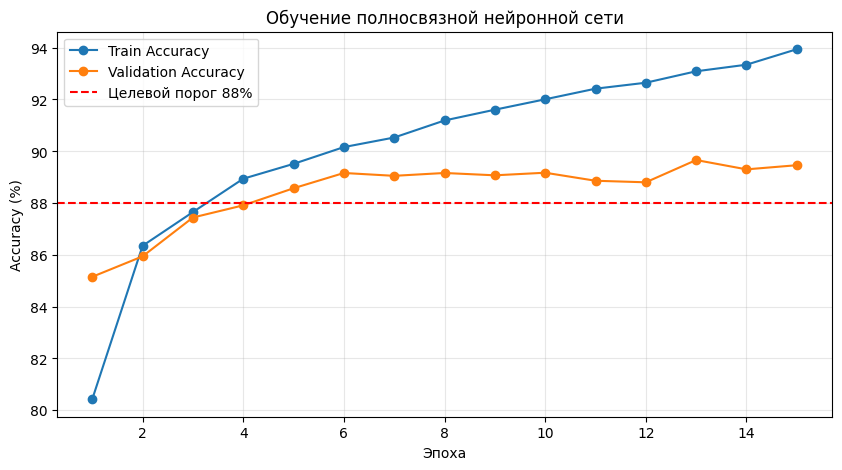

In [11]:
plt.figure(figsize=(10, 5))

plt.plot(
    range(1, EPOCHS + 1),
    train_accuracies,
    label="Train Accuracy",
    marker="o"
)

plt.plot(
    range(1, EPOCHS + 1),
    val_accuracies,
    label="Validation Accuracy",
    marker="o"
)

plt.axhline(
    y=88,
    color="red",
    linestyle="--",
    label="Целевой порог 88%"
)

plt.xlabel("Эпоха")
plt.ylabel("Accuracy (%)")
plt.title("Обучение полносвязной нейронной сети")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [13]:
model.eval()

correct = 0
total = 0

with torch.no_grad():
    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

test_accuracy = 100 * correct / total

print("=" * 45)
print(f"Test Accuracy: {test_accuracy:.2f}%")
print("=" * 45)

if test_accuracy > 88:
    print("✅ ЗАДАНИЕ ВЫПОЛНЕНО!")
    print("Точность на тестовой выборке выше 88%.")
else:
    print("⚠️ Нужно улучшить модель.")

Test Accuracy: 88.45%
✅ ЗАДАНИЕ ВЫПОЛНЕНО!
Точность на тестовой выборке выше 88%.


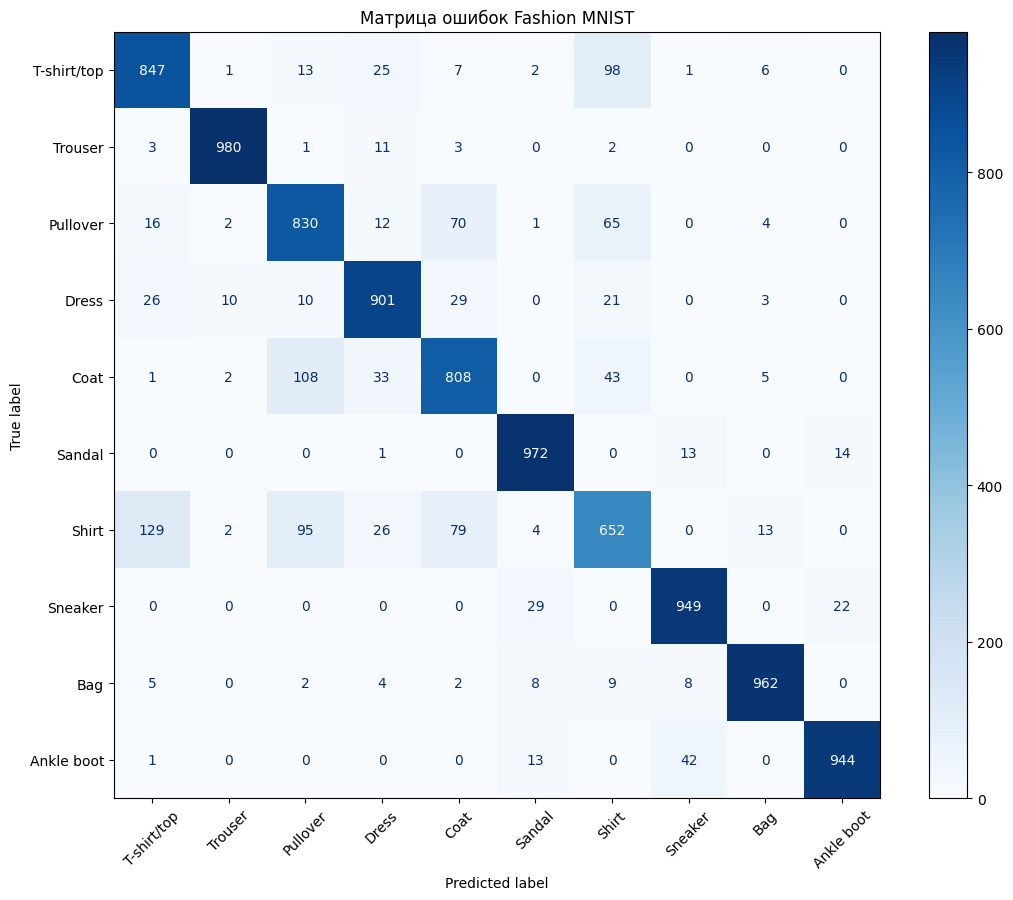

In [15]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

model.eval()
all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        outputs = model(images.to(device))
        preds = outputs.argmax(dim=1).cpu()

        all_preds.extend(preds.numpy())
        all_labels.extend(labels.numpy())

cm = confusion_matrix(all_labels, all_preds)

fig, ax = plt.subplots(figsize=(11, 9))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(ax=ax, cmap="Blues", xticks_rotation=45)
plt.title("Матрица ошибок Fashion MNIST")
plt.tight_layout()
plt.show()

Итоги

В ходе выполнения ДЗ была построена и обучена полносвязная нейронная сеть для классификации изображений Fashion MNIST с использованием PyTorch\.

Архитектура модели:

- Входной слой — 784 признака\.

- Первый скрытый слой — 256 нейронов, ReLU\.

- Второй скрытый слой — 128 нейронов, ReLU\.

- Выходной слой — 10 классов\.

Для обучения использовался оптимизатор Adam, функция потерь CrossEntropyLoss и 15 эпох\.

Результаты:

- Train Accuracy \(15\-я эпоха\) = 93,94%

- Лучшая Validation Accuracy = 89,66%

Вывод: модель успешно обучена и достигла точности 88,45% на тестовой выборке, что превышает установленный порог 88%\. 

<a style='text-decoration:none;line-height:16px;display:flex;color:#5B5B62;padding:10px;justify-content:end;' href='https://deepnote.com?utm_source=created-in-deepnote-cell&projectId=06975d2a-20b8-4e37-9f29-cb3d1f85629c' target="_blank">

Created in <span style='font-weight:600;margin-left:4px;'>Deepnote</span></a>